In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from wordcloud import worldcloud



In [ ]:
df=pd.read_csv("netflix.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
#Renaming the listed in column to geners
df.rename(columns={'listed_in':'genre'},inplace=True)
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genre', 'description'],
      dtype='object')

In [ ]:
#Dropping the show_id column as  it may be of no use in the analysis
df.drop(columns="show_id",inplace=True)

In [ ]:
# Identical rows---- means ny mistake yo enter same data for so many time it also can degrade

#the performance of analysis

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Checking the missing Values
df.isnull().sum()

,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3
genre,0


In [ ]:
# Here we can see clearly here some count are so big and some are so small
# Which is available in less quqntity we can drop them

In [ ]:
#dropping only 10 values---row
df.dropna(subset=['date_added'],inplace=True)
df['date_added'].isna().sum()

np.int64(0)

In [ ]:
#dropping only 4 value---row
df.dropna(subset=["rating"],inplace=True)
df["rating"].isna().sum()

np.int64(0)

In [ ]:
#dropping only 3value---row
df.dropna(subset=["duration"],inplace=True)
df["duration"].isna().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
type,0
title,0
director,2621
cast,825
country,829
date_added,0
release_year,0
rating,0
duration,0
genre,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   type          8790 non-null   object
 1   title         8790 non-null   object
 2   director      6169 non-null   object
 3   cast          7965 non-null   object
 4   country       7961 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   genre         8790 non-null   object
 10  description   8790 non-null   object
dtypes: int64(1), object(10)
memory usage: 824.1+ KB


In [ ]:
#Converting the date added column from object to datetime format
# When there is some mismatch in our date format then that value is replace by null

df["df_added"]=pd.to_datetime(df["date_added"],errors="coerce")
df["date_added"].isnull().sum()

np.int64(0)

In [ ]:
df.dropna(subset=["date_added"],inplace=True)
df["date_added"].isna().sum()

np.int64(0)

In [ ]:
#Adding day, month,year,month_name,day_name as seperate columns to the dataframe

df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df["day"]=df['date_added'].dt.day
df["month"]=df['date_added'].dt.month
df["year"]=df['date_added'].dt.year
df["month_name"]=df['date_added'].dt.month_name()
df["weekday"]=df['date_added'].dt.day_name()
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,df_added,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021-09-24,24.0,9.0,2021.0,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021-09-24,24.0,9.0,2021.0,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021-09-24,24.0,9.0,2021.0,September,Friday


In [ ]:
df["duration"].unique()

array(['90 min', '2 Seasons', '1 Season', '91 min', '125 min',
       '9 Seasons', '104 min', '127 min', '4 Seasons', '67 min', '94 min',
       '5 Seasons', '161 min', '61 min', '166 min', '147 min', '103 min',
       '97 min', '106 min', '111 min', '3 Seasons', '110 min', '105 min',
       '96 min', '124 min', '116 min', '98 min', '23 min', '115 min',
       '122 min', '99 min', '88 min', '100 min', '6 Seasons', '102 min',
       '93 min', '95 min', '85 min', '83 min', '113 min', '13 min',
       '182 min', '48 min', '145 min', '87 min', '92 min', '80 min',
       '117 min', '128 min', '119 min', '143 min', '114 min', '118 min',
       '108 min', '63 min', '121 min', '142 min', '154 min', '120 min',
       '82 min', '109 min', '101 min', '86 min', '229 min', '76 min',
       '89 min', '156 min', '112 min', '107 min', '129 min', '135 min',
       '136 min', '165 min', '150 min', '133 min', '70 min', '84 min',
       '140 min', '78 min', '7 Seasons', '64 min', '59 min', '139 min',
    

In [ ]:
s1="179 min"
int(s1.split()[0])


179

In [ ]:
s1="12 Seasons"
int(s1.split()[0])

12

In [ ]:
df["duration"]=df["duration"].apply(lambda x:int(x.split()[0]))

In [ ]:
df["duration"].unique()

array([ 90,   2,   1,  91, 125,   9, 104, 127,   4,  67,  94,   5, 161,
        61, 166, 147, 103,  97, 106, 111,   3, 110, 105,  96, 124, 116,
        98,  23, 115, 122,  99,  88, 100,   6, 102,  93,  95,  85,  83,
       113,  13, 182,  48, 145,  87,  92,  80, 117, 128, 119, 143, 114,
       118, 108,  63, 121, 142, 154, 120,  82, 109, 101,  86, 229,  76,
        89, 156, 112, 107, 129, 135, 136, 165, 150, 133,  70,  84, 140,
        78,   7,  64,  59, 139,  69, 148, 189, 141, 130, 138,  81, 132,
        10, 123,  65,  68,  66,  62,  74, 131,  39,  46,  38,   8,  17,
       126, 155, 159, 137,  12, 273,  36,  34,  77,  60,  49,  58,  72,
       204, 212,  25,  73,  29,  47,  32,  35,  71, 149,  33,  15,  54,
       224, 162,  37,  75,  79,  55, 158, 164, 173, 181, 185,  21,  24,
        51, 151,  42,  22, 134, 177,  52,  14,  53,  57,  28,  50,  26,
        45, 171,  27,  44, 146,  20, 157, 203,  41,  30, 194, 233, 237,
       230, 195, 253, 152, 190, 160, 208, 180, 144, 174, 170, 19

In [ ]:
# Checking for unique values of rating and categorising them for better understanding

df["rating"].unique()

array(['PG-13', 'TV-MA', 'PG', 'TV-14', 'TV-PG', 'TV-Y', 'TV-Y7', 'R',
       'TV-G', 'G', 'NC-17', 'NR', 'TV-Y7-FV', 'UR'], dtype=object)

In [ ]:
df["rating"]=df["rating"].replace(['TV-Y',"TV-Y7","G","TV-G","TV-PG","PG","TV-Y7-FV"],"kids")
df["rating"]=df["rating"].replace(["PG-13","TV-14"],"Teens")
df["rating"]=df["rating"].replace(["R","TV-MA","NC-17"],"Adults")
df["rating"]=df["rating"].replace(["NR","UR"],np.nan)
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,df_added,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,Teens,90,Documentaries,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,Adults,1,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021-09-24,24.0,9.0,2021.0,September,Friday
3,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,Adults,1,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021-09-24,24.0,9.0,2021.0,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,Adults,2,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021-09-24,24.0,9.0,2021.0,September,Friday


In [ ]:
df["rating"].unique()

array(['Teens', 'Adults', 'kids', nan], dtype=object)

In [ ]:
df["rating"].isna().sum()

np.int64(82)

In [ ]:
df.dropna(subset=["rating"],inplace=True)
df["rating"].isna().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
type,0
title,0
director,2617
cast,808
country,829
date_added,87
release_year,0
rating,0
duration,0
genre,0


In [ ]:
df[(df["director"].isna()) & (df["country"].isna()) & (df["cast"].isna())].shape[0]

96

In [ ]:
df.shape

(8708, 17)

In [ ]:
df.dropna(subset=['director','country','cast'],how='all',inplace=True)
df.shape

(8612, 17)

In [ ]:
df.isna().sum()

,0
type,0
title,0
director,2521
cast,712
country,733
date_added,87
release_year,0
rating,0
duration,0
genre,0


In [ ]:
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,df_added,day,month,year,month_name,weekday
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,Teens,90,Documentaries,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,Adults,1,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021-09-24,24.0,9.0,2021.0,September,Friday
4,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,Adults,2,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021-09-24,24.0,9.0,2021.0,September,Friday
5,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,2021-09-24,2021,Adults,1,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...,2021-09-24,24.0,9.0,2021.0,September,Friday


In [ ]:
df["cast"][2]

'Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera'

In [ ]:
df_cast=pd.DataFrame(df["cast"].apply(lambda x: str(x).split(', ')).tolist(),index=df["title"])
df_cast

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
title,,,,,,,,,,,,,,,,,,,,,
Dick Johnson Is Dead,nan,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
Blood & Water,Ama Qamata,Khosi Ngema,Gail Mabalane,Thabang Molaba,Dillon Windvogel,Natasha Thahane,Arno Greeff,Xolile Tshabalala,Getmore Sithole,Cindy Mahlangu,...,None,None,None,None,None,None,None,None,None,None
Ganglands,Sami Bouajila,Tracy Gotoas,Samuel Jouy,Nabiha Akkari,Sofia Lesaffre,Salim Kechiouche,Noureddine Farihi,Geert Van Rampelberg,Bakary Diombera,None,...,None,None,None,None,None,None,None,None,None,None
Kota Factory,Mayur More,Jitendra Kumar,Ranjan Raj,Alam Khan,Ahsaas Channa,Revathi Pillai,Urvi Singh,Arun Kumar,None,None,...,None,None,None,None,None,None,None,None,None,None
Midnight Mass,Kate Siegel,Zach Gilford,Hamish Linklater,Henry Thomas,Kristin Lehman,Samantha Sloyan,Igby Rigney,Rahul Kohli,Annarah Cymone,Annabeth Gish,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zinzana,Ali Suliman,Saleh Bakri,Yasa,Ali Al-Jabri,Mansoor Alfeeli,Ahd,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
Zodiac,Mark Ruffalo,Jake Gyllenhaal,Robert Downey Jr.,Anthony Edwards,Brian Cox,Elias Koteas,Donal Logue,John Carroll Lynch,Dermot Mulroney,Chloë Sevigny,...,None,None,None,None,None,None,None,None,None,None
Zombieland,Jesse Eisenberg,Woody Harrelson,Emma Stone,Abigail Breslin,Amber Heard,Bill Murray,Derek Graf,None,None,None,...,None,None,None,None,None,None,None,None,None,None


In [ ]:
df_cast=df_cast.stack()
df_cast

title                  
Dick Johnson Is Dead  0                      nan
Blood & Water         0               Ama Qamata
                      1              Khosi Ngema
                      2            Gail Mabalane
                      3           Thabang Molaba
                                   ...          
Zubaan                3         Manish Chaudhary
                      4             Meghna Malik
                      5            Malkeet Rauni
                      6           Anita Shabdish
                      7    Chittaranjan Tripathy
Length: 64251, dtype: object

In [ ]:
df_cast=pd.DataFrame(df_cast)
df_cast

0
title                                        
Dick Johnson Is Dead 0                    nan
Blood & Water        0             Ama Qamata
                     1            Khosi Ngema
                     2          Gail Mabalane
                     3         Thabang Molaba
...                                       ...
Zubaan               3       Manish Chaudhary
                     4           Meghna Malik
                     5          Malkeet Rauni
                     6         Anita Shabdish
                     7  Chittaranjan Tripathy

[64251 rows x 1 columns]

In [ ]:
df_cast.reset_index(inplace=True)
df_cast

,title,level_1,0
0,Dick Johnson Is Dead,0,nan
1,Blood & Water,0,Ama Qamata
2,Blood & Water,1,Khosi Ngema
3,Blood & Water,2,Gail Mabalane
4,Blood & Water,3,Thabang Molaba
...,...,...,...
64246,Zubaan,3,Manish Chaudhary
64247,Zubaan,4,Meghna Malik
64248,Zubaan,5,Malkeet Rauni
64249,Zubaan,6,Anita Shabdish


In [ ]:
df_cast=df_cast[["title",0]]
df_cast

,title,0
0,Dick Johnson Is Dead,nan
1,Blood & Water,Ama Qamata
2,Blood & Water,Khosi Ngema
3,Blood & Water,Gail Mabalane
4,Blood & Water,Thabang Molaba
...,...,...
64246,Zubaan,Manish Chaudhary
64247,Zubaan,Meghna Malik
64248,Zubaan,Malkeet Rauni
64249,Zubaan,Anita Shabdish


In [ ]:
df_cast.columns=["title","cast"]
df_cast

,title,cast
0,Dick Johnson Is Dead,nan
1,Blood & Water,Ama Qamata
2,Blood & Water,Khosi Ngema
3,Blood & Water,Gail Mabalane
4,Blood & Water,Thabang Molaba
...,...,...
64246,Zubaan,Manish Chaudhary
64247,Zubaan,Meghna Malik
64248,Zubaan,Malkeet Rauni
64249,Zubaan,Anita Shabdish


In [ ]:
df_cast.replace("nan",np.nan,inplace=True)
df_cast.isna().sum()

/tmp/ipykernel_708/356088169.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cast.replace("nan",np.nan,inplace=True)


,0
title,0
cast,712


In [ ]:
df_genre=pd.DataFrame(df["genre"].apply(lambda x:str(x).split(', ')).tolist(),index=df['title'])
df_genre=df_genre.stack()
df_genre=pd.DataFrame(df_genre)
df_genre.reset_index(inplace=True)
df_genre=df_genre[["title",0]]
df_genre.columns=["title","genres"]
df_genre.replace("nan",np.nan,inplace=True)
df_genre.isna().sum()

,0
title,0
genres,0


In [ ]:
df_director=pd.DataFrame(df["director"].apply(lambda x:str(x).split(',' )).tolist(),index=df['title'])
df_director=df_director.stack()
df_director=pd.DataFrame(df_director)
df_director.reset_index(inplace=True)
df_director=df_director[["title",0]]
df_director.columns=["title","director"]
df_director.replace("nan",np.nan,inplace=True)
df_director.isna().sum()

,0
title,0
director,2521


In [ ]:
df_country=pd.DataFrame(df["country"].apply(lambda x:str(x).split(',' )).tolist(),index=df['title'])
df_country=df_country.stack()
df_country=pd.DataFrame(df_country)
df_country.reset_index(inplace=True)
df_country=df_country[["title",0]]
df_country.columns=["title","country"]
df_country.replace("nan",np.nan,inplace=True)
df_country.isna().sum()

,0
title,0
country,733


In [ ]:
df12=df_cast.merge(df_genre,on="title")
df12

,title,cast,genres
0,Dick Johnson Is Dead,NaN,Documentaries
1,Blood & Water,Ama Qamata,International TV Shows
2,Blood & Water,Ama Qamata,TV Dramas
3,Blood & Water,Ama Qamata,TV Mysteries
4,Blood & Water,Khosi Ngema,International TV Shows
...,...,...,...
147927,Zubaan,Anita Shabdish,International Movies
147928,Zubaan,Anita Shabdish,Music & Musicals
147929,Zubaan,Chittaranjan Tripathy,Dramas
147930,Zubaan,Chittaranjan Tripathy,International Movies


In [ ]:
df123=df_director.merge(df12,on="title")
df123

,title,director,cast,genres
0,Dick Johnson Is Dead,Kirsten Johnson,NaN,Documentaries
1,Blood & Water,NaN,Ama Qamata,International TV Shows
2,Blood & Water,NaN,Ama Qamata,TV Dramas
3,Blood & Water,NaN,Ama Qamata,TV Mysteries
4,Blood & Water,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...
159583,Zubaan,Mozez Singh,Anita Shabdish,International Movies
159584,Zubaan,Mozez Singh,Anita Shabdish,Music & Musicals
159585,Zubaan,Mozez Singh,Chittaranjan Tripathy,Dramas
159586,Zubaan,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df1234 = df_country.merge(df123, on="title")
df1234

,title,country,director,cast,genres
0,Dick Johnson Is Dead,United States,Kirsten Johnson,NaN,Documentaries
1,Blood & Water,South Africa,NaN,Ama Qamata,International TV Shows
2,Blood & Water,South Africa,NaN,Ama Qamata,TV Dramas
3,Blood & Water,South Africa,NaN,Ama Qamata,TV Mysteries
4,Blood & Water,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...
200019,Zubaan,India,Mozez Singh,Anita Shabdish,International Movies
200020,Zubaan,India,Mozez Singh,Anita Shabdish,Music & Musicals
200021,Zubaan,India,Mozez Singh,Chittaranjan Tripathy,Dramas
200022,Zubaan,India,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df_new=df.merge(df1234,on="title")
df_new

,type,title,director_x,cast_x,country_x,date_added,release_year,rating,duration,genre,...,df_added,day,month,year,month_name,weekday,country_y,director_y,cast_y,genres
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,Teens,90,Documentaries,...,2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries",...,2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries",...,2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries",...,2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,Adults,2,"International TV Shows, TV Dramas, TV Mysteries",...,2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200019,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,Teens,111,"Dramas, International Movies, Music & Musicals",...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,International Movies
200020,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,Teens,111,"Dramas, International Movies, Music & Musicals",...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,Music & Musicals
200021,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,Teens,111,"Dramas, International Movies, Music & Musicals",...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,Dramas
200022,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,Teens,111,"Dramas, International Movies, Music & Musicals",...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df_new.drop(columns=["cast_x", "director_x", "genre"], inplace=True)
df_new

,type,title,country_x,date_added,release_year,rating,duration,description,df_added,day,month,year,month_name,weekday,country_y,director_y,cast_y,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200019,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,International Movies
200020,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,Music & Musicals
200021,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,Dramas
200022,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df_new.rename(columns={"country_y":"country","director_y":"director","cast_y":"cast"},inplace=True)
df_new

,type,title,country_x,date_added,release_year,rating,duration,description,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200019,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,International Movies
200020,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,Music & Musicals
200021,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,Dramas
200022,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df_new.head()

,type,title,country_x,date_added,release_year,rating,duration,description,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,NaN,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,NaN,Khosi Ngema,International TV Shows


In [ ]:
df_new.shape

(200024, 18)

In [ ]:
df_new.isnull().sum()

,0
type,0
title,0
country_x,11710
date_added,1546
release_year,0
rating,0
duration,0
description,0
df_added,1546
day,1546


In [ ]:
df_new["cast"]=df_new["cast"].replace(np.nan,"Unknown")
df_new["director"]=df_new["director"].replace(np.nan,"Unknown")
df_new["country"]=df_new["country"].replace(np.nan,"Unknown")
df_new


,type,title,country_x,date_added,release_year,rating,duration,description,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,Unknown,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Khosi Ngema,International TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200019,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,International Movies
200020,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Anita Shabdish,Music & Musicals
200021,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,Dramas
200022,Movie,Zubaan,India,2019-03-02,2015,Teens,111,A scrappy but poor boy worms his way into a ty...,2019-03-02,2.0,3.0,2019.0,March,Saturday,India,Mozez Singh,Chittaranjan Tripathy,International Movies


In [ ]:
df_new.head()

,type,title,country_x,date_added,release_year,rating,duration,description,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,"As her father nears the end of his life, filmm...",2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,Unknown,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,International TV Shows
2,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,TV Dramas
3,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,TV Mysteries
4,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,"After crossing paths at a party, a Cape Town t...",2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Khosi Ngema,International TV Shows


In [ ]:
df_new.drop(["description"], axis=1, inplace=True, errors='ignore')

In [ ]:
df_new.duplicated().sum()

np.int64(7)

In [ ]:
df_new.drop_duplicates(keep='first',inplace=True)


In [ ]:
df_movies=df_new[df_new["type"]=="Movie"]
df_tvs=df[df_new["type"]=="TV Show"]

/tmp/ipykernel_708/3120957642.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_tvs=df[df_new["type"]=="TV Show"]


In [ ]:
df_movies.shape

(144362, 17)

In [ ]:
df_tvs.shape

(2371, 17)

In [ ]:
df_tvs.rename(columns={"duration":"seasons"},inplace=True)

/tmp/ipykernel_708/2462203523.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tvs.rename(columns={"duration":"seasons"},inplace=True)


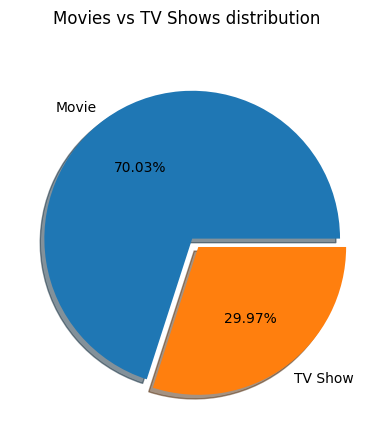

In [ ]:
#Start our Visualisation
plt.pie(df['type'].value_counts(),labels=df["type"].value_counts().index,autopct="%.2f%%",explode=[0.03,0.04],shadow=True)
plt.suptitle("Movies vs TV Shows distribution")
plt.show()

In [ ]:
df_temp=df_new.drop_duplicates(subset=["country","title"])
df_temp

,type,title,country_x,date_added,release_year,rating,duration,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,Unknown,Documentaries
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,Adults,2,2021-09-24,24.0,9.0,2021.0,September,Friday,South Africa,Unknown,Ama Qamata,International TV Shows
58,TV Show,Ganglands,NaN,2021-09-24,2021,Adults,1,2021-09-24,24.0,9.0,2021.0,September,Friday,Unknown,Julien Leclercq,Sami Bouajila,Crime TV Shows
85,TV Show,Kota Factory,India,2021-09-24,2021,Adults,2,2021-09-24,24.0,9.0,2021.0,September,Friday,India,Unknown,Mayur More,International TV Shows
109,TV Show,Midnight Mass,NaN,2021-09-24,2021,Adults,1,2021-09-24,24.0,9.0,2021.0,September,Friday,Unknown,Mike Flanagan,Kate Siegel,TV Dramas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199920,Movie,Zinzana,"United Arab Emirates, Jordan",2016-03-09,2015,Adults,96,2016-03-09,9.0,3.0,2016.0,March,Wednesday,Jordan,Majid Al Ansari,Ali Suliman,Dramas
199938,Movie,Zodiac,United States,2019-11-20,2007,Adults,158,2019-11-20,20.0,11.0,2019.0,November,Wednesday,United States,David Fincher,Mark Ruffalo,Cult Movies
199968,Movie,Zombieland,United States,2019-11-01,2009,Adults,88,2019-11-01,1.0,11.0,2019.0,November,Friday,United States,Ruben Fleischer,Jesse Eisenberg,Comedies
199982,Movie,Zoom,United States,2020-01-11,2006,kids,88,2020-01-11,11.0,1.0,2020.0,January,Saturday,United States,Peter Hewitt,Tim Allen,Children & Family Movies


In [ ]:
x=df_temp["country"].value_counts().head(10)
x

,count
country,
United States,3166
India,1004
Unknown,733
United Kingdom,617
United States,472
Canada,267
Japan,257
France,210
South Korea,208


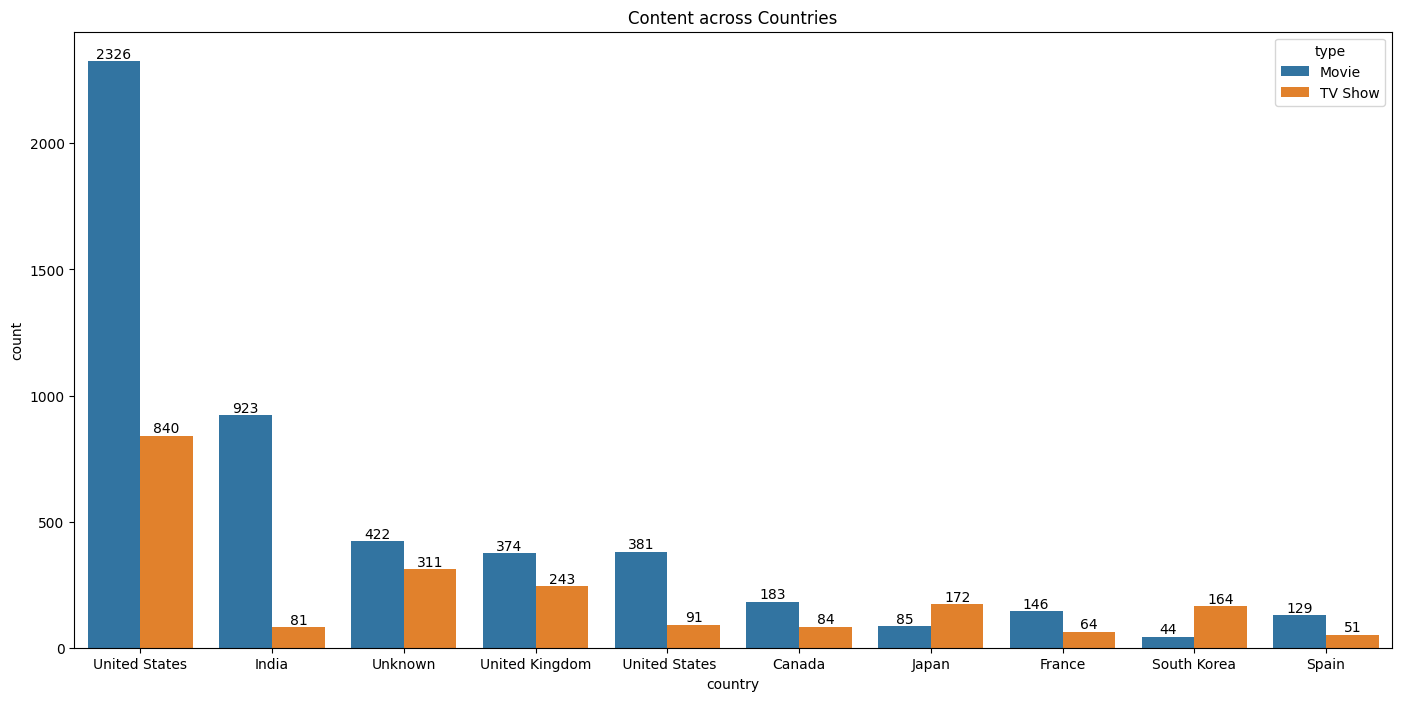

In [ ]:
plt.figure(figsize=(17,8))
plt.title("Content across Countries")
label=sns.countplot(data=df_temp,x="country",hue="type",order=x.index)
for i in label.containers:
  label.bar_label(i)
plt.show()

/tmp/ipykernel_708/2509367928.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='director', order = x.index,palette="husl")
/tmp/ipykernel_708/2509367928.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='director', order = y.index,palette="husl")


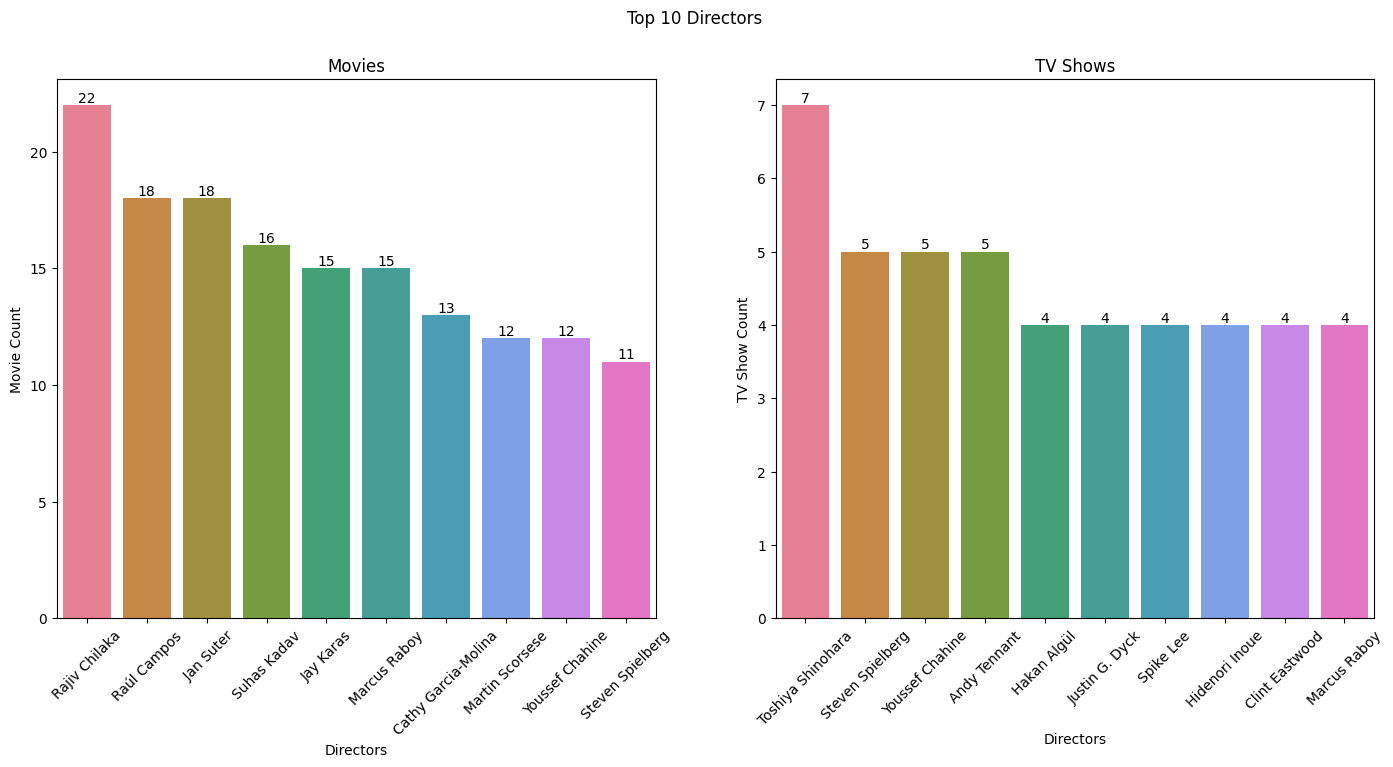

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['director','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['director','title'])

plt.figure(figsize = (17,7))
plt.suptitle('Top 10 Directors')

plt.subplot(1,2,1)
x=df_movies_temp['director'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='director', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('Directors')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['director'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='director', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('Directors')
plt.ylabel('TV Show Count')
plt.show()

/tmp/ipykernel_708/1547316479.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='genres', order = x.index,palette="husl")
/tmp/ipykernel_708/1547316479.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='genre', order = y.index,palette="husl")


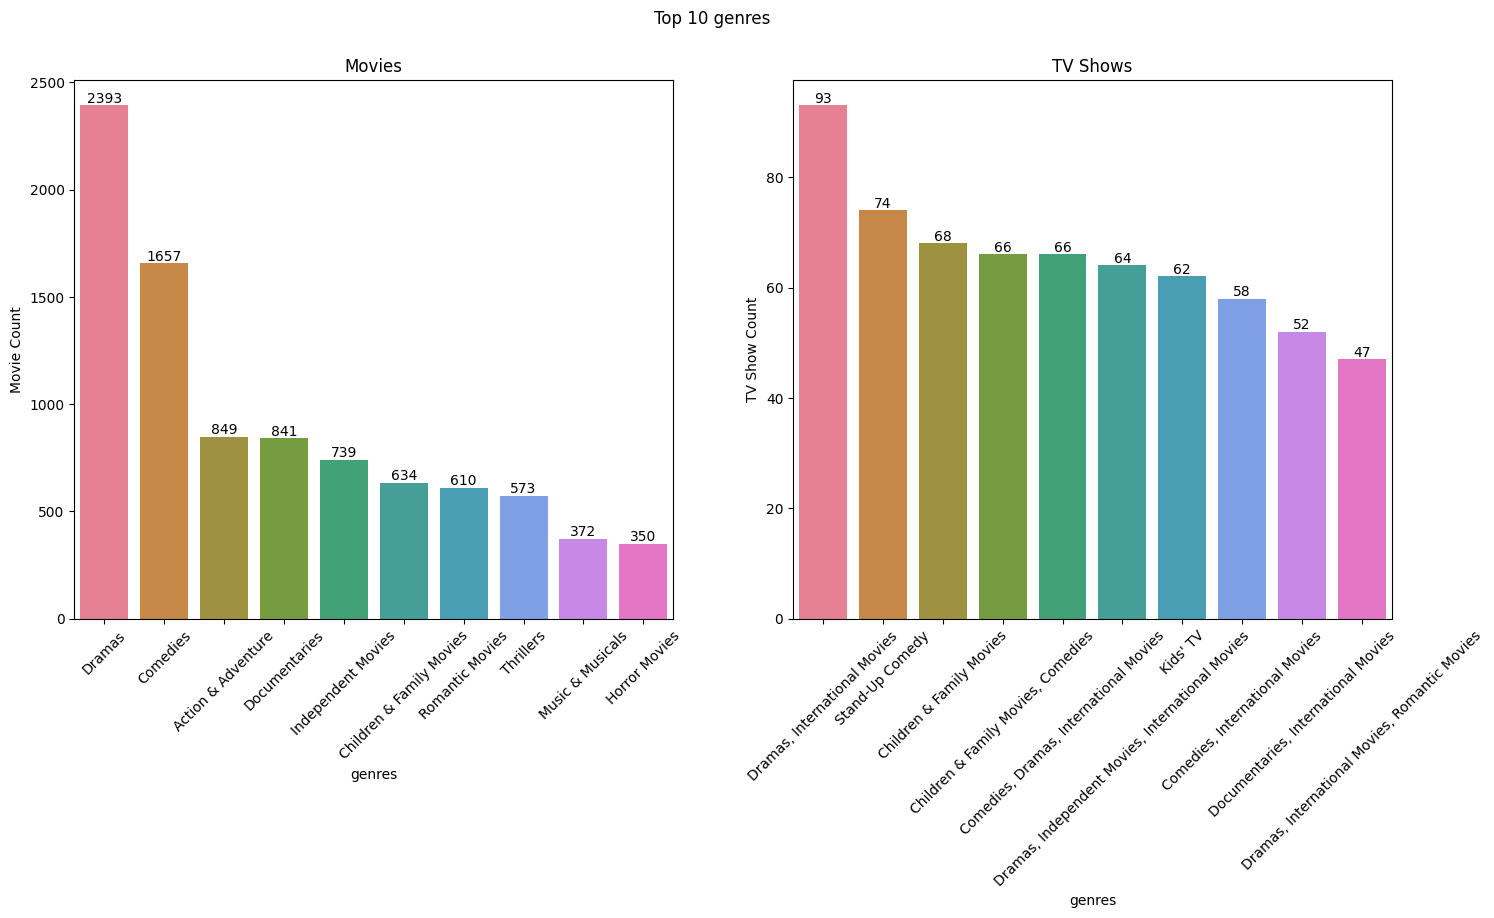

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['genres','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['genre','title'])

plt.figure(figsize = (17,7))
plt.suptitle('Top 10 genres')

plt.subplot(1,2,1)
x=df_movies_temp['genres'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='genres', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('genres')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['genre'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='genre', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('genres')
plt.ylabel('TV Show Count')
plt.show()

/tmp/ipykernel_708/4184701122.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='cast', order = x.index,palette="husl")
/tmp/ipykernel_708/4184701122.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_tvs_temp, x='cast', order = y.index,palette="husl")


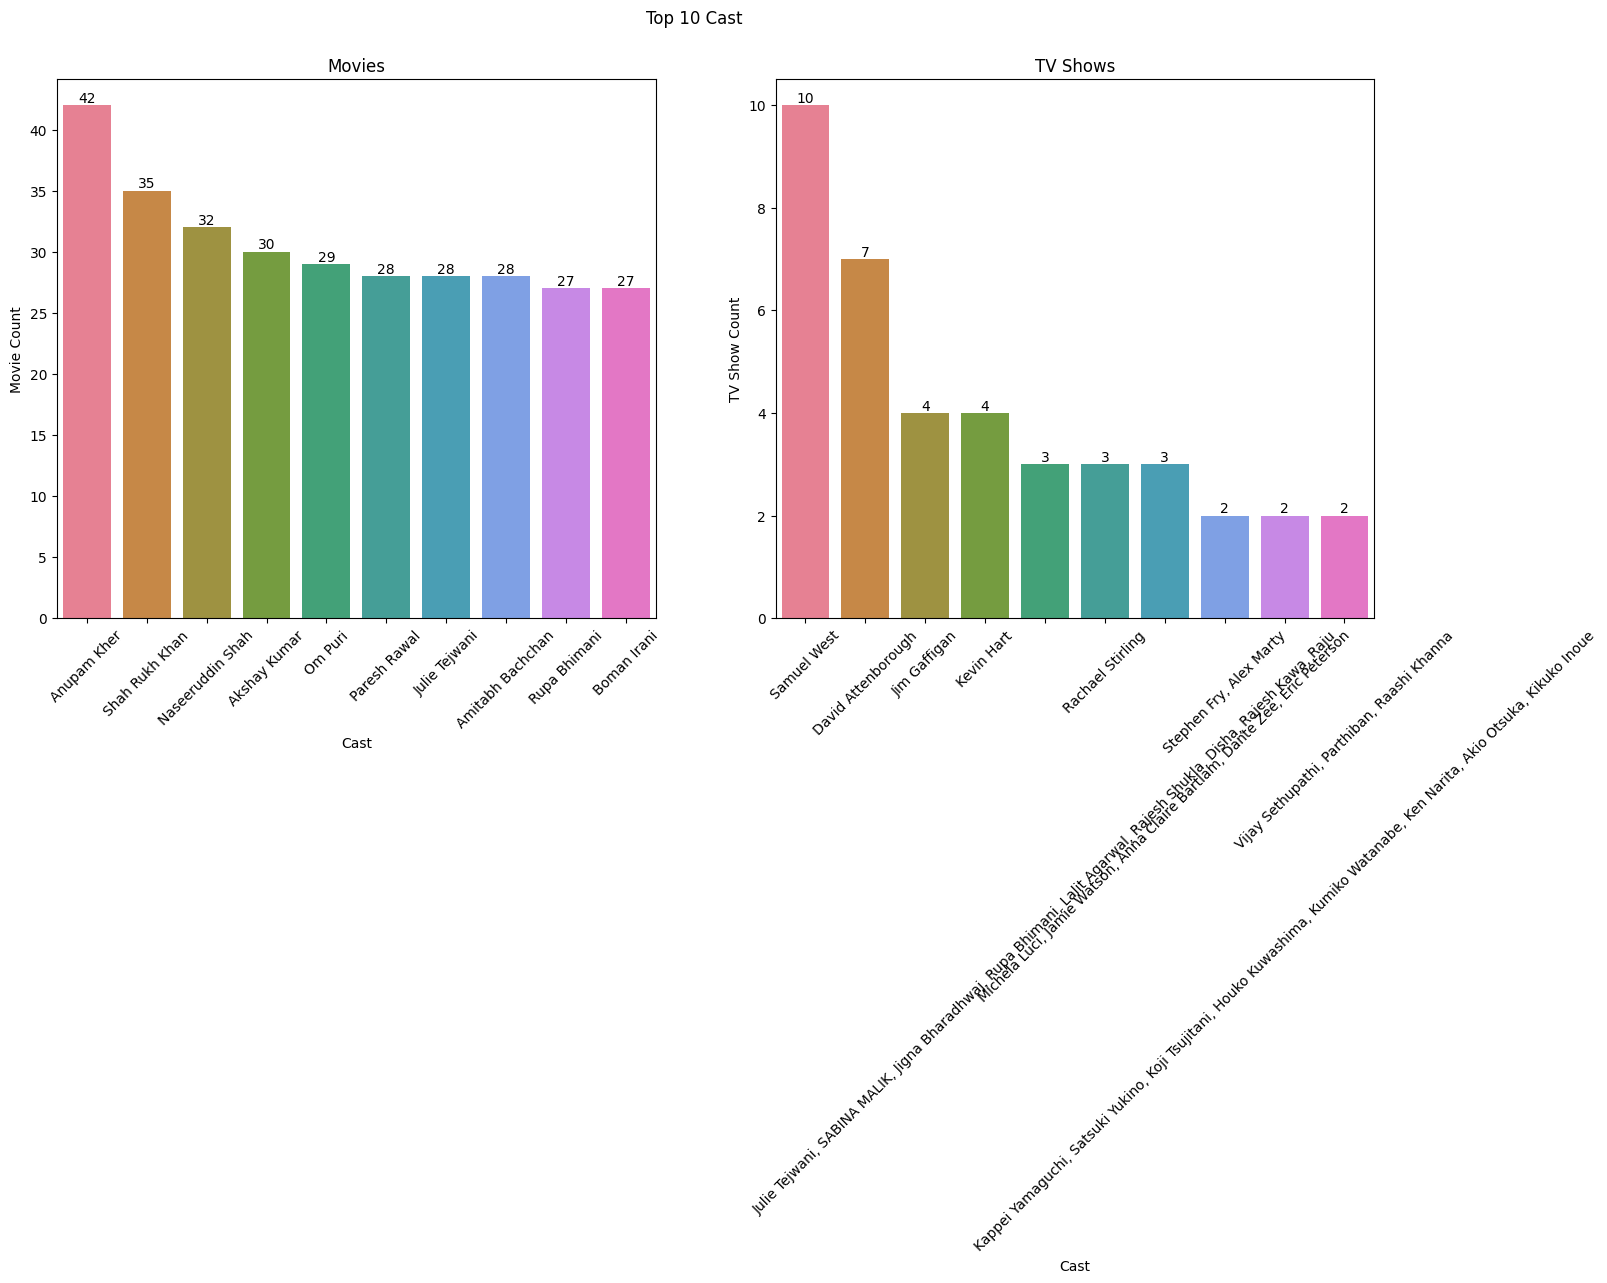

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['cast','title'])
df_tvs_temp = df_tvs.drop_duplicates(subset = ['cast','title'])

plt.figure(figsize = (17,7))
plt.suptitle('Top 10 Cast')

plt.subplot(1,2,1)
x=df_movies_temp['cast'].value_counts()[1:11]
label = sns.countplot(data=df_movies_temp, x='cast', order = x.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("Movies")
plt.xticks(rotation=45)
plt.xlabel('Cast')
plt.ylabel('Movie Count')

plt.subplot(1,2,2)
y=df_tvs_temp['cast'].value_counts()[1:11]
label = sns.countplot(data=df_tvs_temp, x='cast', order = y.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.title("TV Shows")
plt.xticks(rotation=45)
plt.xlabel('Cast')
plt.ylabel('TV Show Count')
plt.show()

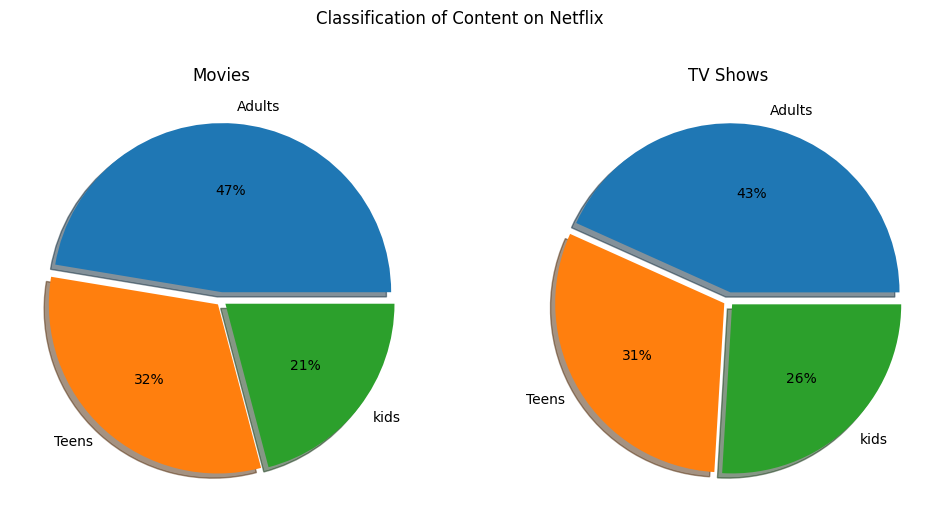

In [ ]:
df_movies_temp = df_movies.drop_duplicates (subset = ['rating', 'title'])
df_tvs_temp = df_tvs.drop_duplicates (subset = ['rating', 'title'])
plt.figure(figsize = (12,6))
plt.suptitle('Classification of Content on Netflix')
plt.subplot(1,2,1)
plt.pie(df_movies_temp['rating'].value_counts(),
labels = df_movies_temp['rating'].value_counts().index,
autopct='%0.0f%%', explode = (0.05,0.03,0.03), shadow = True)
plt.title('Movies')
plt.subplot(1,2,2)
plt.pie(df_tvs_temp['rating'].value_counts(),
labels = df_tvs_temp['rating'].value_counts().index,
autopct='%0.0f%%', explode = (0.05,0.03,0.03), shadow = True)

plt.title('TV Shows')

plt.show()

In [ ]:
df_movies_temp=df_movies.drop_duplicates(subset=["year","title"])
df_movies_temp

,type,title,country_x,date_added,release_year,rating,duration,df_added,day,month,year,month_name,weekday,country,director,cast,genres
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2020,Teens,90,2021-09-25,25.0,9.0,2021.0,September,Saturday,United States,Kirsten Johnson,Unknown,Documentaries
157,Movie,My Little Pony: A New Generation,NaN,2021-09-24,2021,kids,91,2021-09-24,24.0,9.0,2021.0,September,Friday,Unknown,Robert Cullen,Vanessa Hudgens,Children & Family Movies
177,Movie,Sankofa,"United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,Adults,125,2021-09-24,24.0,9.0,2021.0,September,Friday,United States,Haile Gerima,Kofi Ghanaba,Dramas
329,Movie,The Starling,United States,2021-09-24,2021,Teens,104,2021-09-24,24.0,9.0,2021.0,September,Friday,United States,Theodore Melfi,Melissa McCarthy,Comedies
426,Movie,Je Suis Karl,"Germany, Czech Republic",2021-09-23,2021,Adults,127,2021-09-23,23.0,9.0,2021.0,September,Thursday,Germany,Christian Schwochow,Luna Wedler,Dramas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199902,Movie,Zinzana,"United Arab Emirates, Jordan",2016-03-09,2015,Adults,96,2016-03-09,9.0,3.0,2016.0,March,Wednesday,United Arab Emirates,Majid Al Ansari,Ali Suliman,Dramas
199938,Movie,Zodiac,United States,2019-11-20,2007,Adults,158,2019-11-20,20.0,11.0,2019.0,November,Wednesday,United States,David Fincher,Mark Ruffalo,Cult Movies
199968,Movie,Zombieland,United States,2019-11-01,2009,Adults,88,2019-11-01,1.0,11.0,2019.0,November,Friday,United States,Ruben Fleischer,Jesse Eisenberg,Comedies
199982,Movie,Zoom,United States,2020-01-11,2006,kids,88,2020-01-11,11.0,1.0,2020.0,January,Saturday,United States,Peter Hewitt,Tim Allen,Children & Family Movies


In [ ]:
mv_year=df_movies_temp["year"].value_counts()
mv_year.sort_index(inplace=True)
mv_year

,count
year,
2008.0,1
2009.0,2
2011.0,13
2012.0,3
2013.0,3
2014.0,19
2015.0,51
2016.0,224
2017.0,813


/tmp/ipykernel_708/3341213338.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
/tmp/ipykernel_708/3341213338.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='month_name',
/tmp/ipykernel_708/3341213338.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='weekday',


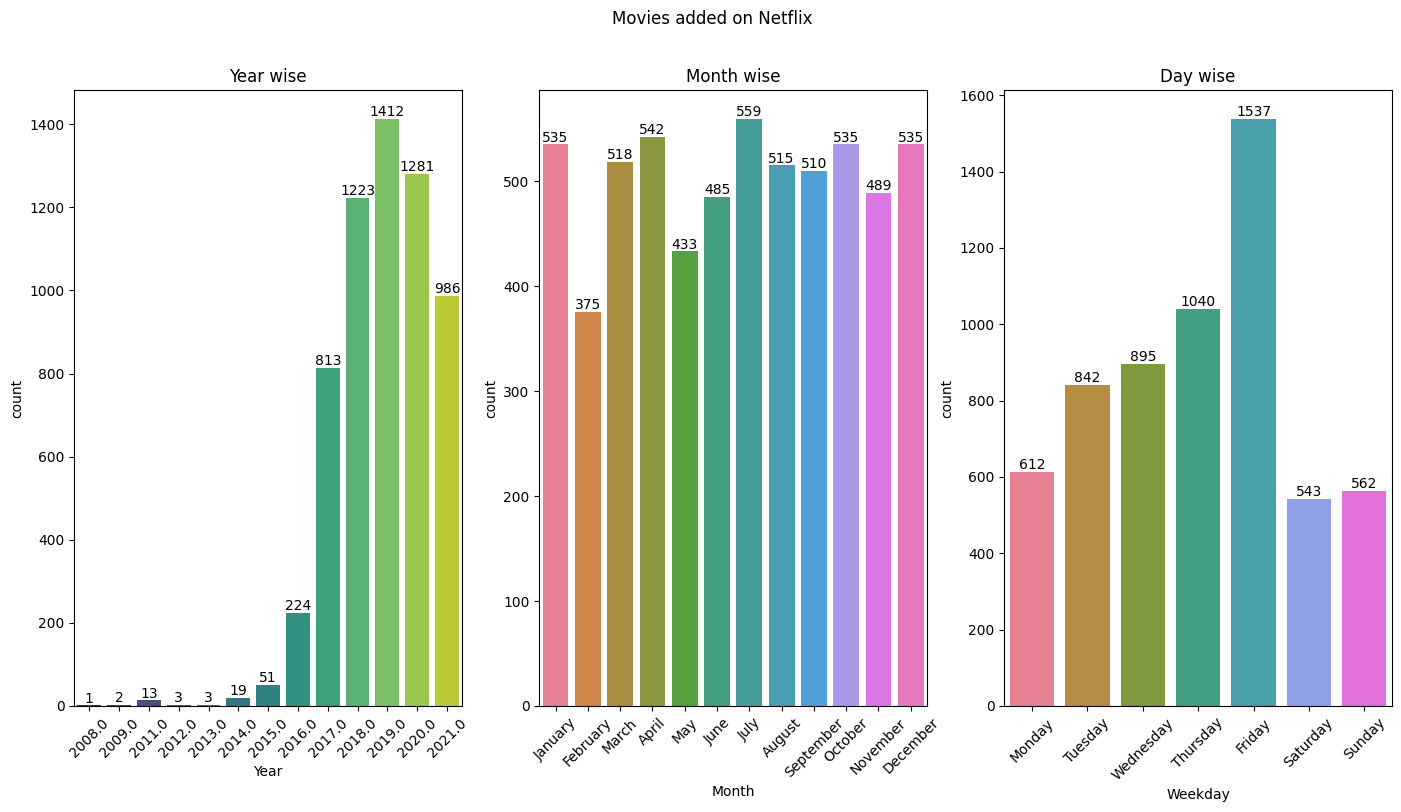

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['year','title'])
df_movies_temp


mv_year = df_movies_temp['year'].value_counts()
mv_year.sort_index(inplace=True)
mv_year

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July','August', 'September',
               'October', 'November', 'December']
mv_month = df_movies_temp['month_name'].value_counts().loc[month_order]
mv_month


day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
mv_day = df_movies_temp['weekday'].value_counts().loc[day_order]
mv_day

plt.figure(figsize=(17,8))
plt.suptitle('Movies added on Netflix')

plt.subplot(1,3,1)
label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise')

plt.subplot(1,3,2)
label = sns.countplot(data=df_movies_temp, x='month_name',
                      order = mv_month.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise')

plt.subplot(1,3,3)
label = sns.countplot(data=df_movies_temp, x='weekday',
                      order = mv_day.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Weekday')
plt.title('Day wise')
plt.show()

/tmp/ipykernel_708/3341213338.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
/tmp/ipykernel_708/3341213338.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='month_name',
/tmp/ipykernel_708/3341213338.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  label = sns.countplot(data=df_movies_temp, x='weekday',


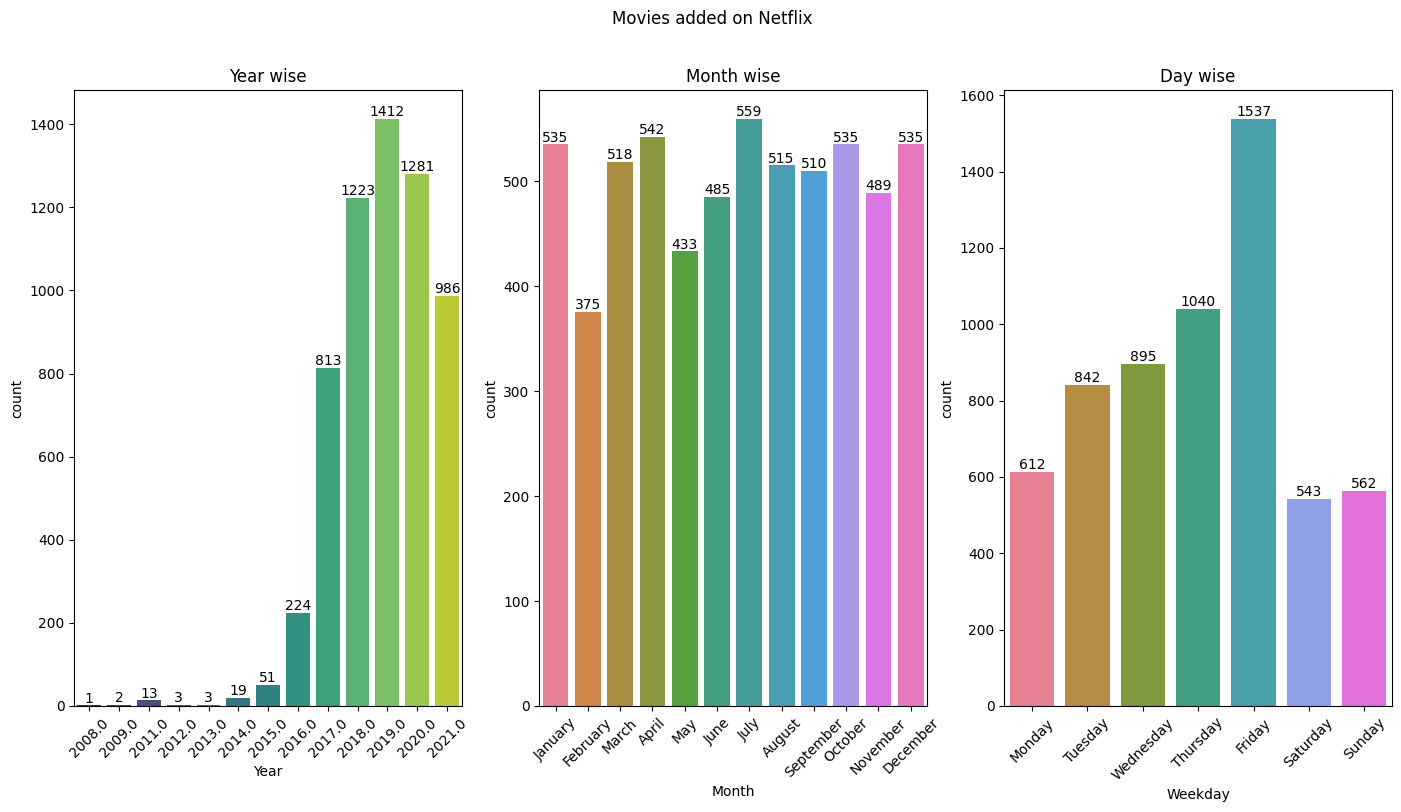

In [ ]:
df_movies_temp = df_movies.drop_duplicates(subset = ['year','title'])
df_movies_temp


mv_year = df_movies_temp['year'].value_counts()
mv_year.sort_index(inplace=True)
mv_year

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July','August', 'September',
               'October', 'November', 'December']
mv_month = df_movies_temp['month_name'].value_counts().loc[month_order]
mv_month


day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
mv_day = df_movies_temp['weekday'].value_counts().loc[day_order]
mv_day

plt.figure(figsize=(17,8))
plt.suptitle('Movies added on Netflix')

plt.subplot(1,3,1)
label = sns.countplot(data=df_movies_temp, x='year', order = mv_year.index,palette="viridis")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Year')
plt.title('Year wise')

plt.subplot(1,3,2)
label = sns.countplot(data=df_movies_temp, x='month_name',
                      order = mv_month.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.title('Month wise')

plt.subplot(1,3,3)
label = sns.countplot(data=df_movies_temp, x='weekday',
                      order = mv_day.index,palette="husl")
for i in label.containers:
    label.bar_label(i)
plt.xticks(rotation=45)
plt.xlabel('Weekday')
plt.title('Day wise')
plt.show()